<center><h1>Dong_Fengkai_HW7</h1></center>

Name: Fengkai Dong
<br>
Github Username: dfk0411
<br>
USC ID: 

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")
x = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1)

### (b) Train a classifier for each label

#### (i) Research

Exact Match: Measures the proportion of samples for which the predicted set of labels exactly match with the true set of labels.

Hamming Loss: Measures the proportion of incorrectly predicted labels across all labels. Unlike exact match, hamming loss allows partially correct predictions.

Hamming Score: Measures the proportion of correctly predicted labels across all labels. It equals one minus the Hamming loss.

#### (ii) Train a SVM for each of the labels

In [ ]:
rbf = {}
rbf_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
    ])
    param_grid = {
        "svm__estimator__C": np.logspace(-3, 5, 20),
        "svm__estimator__gamma": np.logspace(-4, 1, 20)
    }
    grid_search = GridSearchCV(
        pipe,
        param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    grid_search.fit(x_train, y_train[label])
    rbf[label] = grid_search.best_estimator_
    rbf_pred[label] = grid_search.predict(x_test)
    print(f"{label}:")
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"CV accuracy: {grid_search.best_score_}")
    print(f"Test accuracy: {accuracy_score(y_test[label], rbf_pred[label])}\n")

match = rbf_pred.eq(y_test)
exact_match = match.all(axis=1).mean()
hamming_score = match.to_numpy().mean()
hamming_loss = 1 - hamming_score
print(f"Exact Match: {exact_match}")
print(f"Hamming Score: {hamming_score}")
print(f"Hamming Loss: {hamming_loss}")

Family:
Best parameters: {'svm__estimator__C': np.float64(42.81332398719396), 'svm__estimator__gamma': np.float64(0.023357214690901212)}
CV accuracy: 0.9912611631796523
Test accuracy: 0.9888837424733673

Genus:
Best parameters: {'svm__estimator__C': np.float64(42.81332398719396), 'svm__estimator__gamma': np.float64(0.04281332398719392)}
CV accuracy: 0.9908674934519863
Test accuracy: 0.9898100972672533

Species:
Best parameters: {'svm__estimator__C': np.float64(6.158482110660261), 'svm__estimator__gamma': np.float64(0.04281332398719392)}
CV accuracy: 0.9898734576666982
Test accuracy: 0.9888837424733673

Exact Match: 0.9833256137100509
Hamming Score: 0.9891925274046627
Hamming Loss: 0.01080747259533732


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [ ]:
l1 = {}
l1_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=1)))
    ])
    grid_search = GridSearchCV(
        pipe,
        {"svm__estimator__C": np.logspace(-3, 5, 20)},
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    grid_search.fit(x_train, y_train[label])
    l1[label] = grid_search.best_estimator_
    l1_pred[label] = grid_search.predict(x_test)
    print(f"{label}:")
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"CV accuracy: {grid_search.best_score_}")
    print(f"Test accuracy: {accuracy_score(y_test[label], l1_pred[label])}\n")

match = l1_pred.eq(y_test)
exact_match = match.all(axis=1).mean()
hamming_score = match.to_numpy().mean()
hamming_loss = 1 - hamming_score
print(f"Exact Match: {exact_match}")
print(f"Hamming Score: {hamming_score}")
print(f"Hamming Loss: {hamming_loss}")

Family:
Best parameters: {'svm__estimator__C': np.float64(0.8858667904100823)}
CV accuracy: 0.9384403894095742
Test accuracy: 0.9333024548402038

Genus:
Best parameters: {'svm__estimator__C': np.float64(112.88378916846884)}
CV accuracy: 0.9551248067152638
Test accuracy: 0.9476609541454377

Species:
Best parameters: {'svm__estimator__C': np.float64(2.3357214690901213)}
CV accuracy: 0.9584997948815046
Test accuracy: 0.9569245020842982

Exact Match: 0.9133858267716536
Hamming Score: 0.9459626370233133
Hamming Loss: 0.05403736297668671


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [ ]:
smote = {}
smote_pred = pd.DataFrame(index=y_test.index)
for label in y_train.columns:
    pipe = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=1)),
        ("svm", OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=30000, random_state=1)))
    ])
    grid_search = GridSearchCV(
        pipe,
        {"svm__estimator__C": np.logspace(-3, 5, 20)},
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    grid_search.fit(x_train, y_train[label])
    smote[label] = grid_search.best_estimator_
    smote_pred[label] = grid_search.predict(x_test)
    print(f"{label}:")
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"CV accuracy: {grid_search.best_score_}")
    print(f"Test accuracy: {accuracy_score(y_test[label], smote_pred[label])}\n")

match = smote_pred.eq(y_test)
exact_match = match.all(axis=1).mean()
hamming_score = match.to_numpy().mean()
hamming_loss = 1 - hamming_score
print(f"Exact Match: {exact_match}")
print(f"Hamming Score: {hamming_score}")
print(f"Hamming Loss: {hamming_loss}")

Family:
Best parameters: {'svm__estimator__C': np.float64(6.158482110660261)}
CV accuracy: 0.9308955789075073
Test accuracy: 0.9268179712830014

Genus:
Best parameters: {'svm__estimator__C': np.float64(0.8858667904100823)}
CV accuracy: 0.920969421565843
Test accuracy: 0.9268179712830014

Species:
Best parameters: {'svm__estimator__C': np.float64(0.04832930238571752)}
CV accuracy: 0.9547271924011487
Test accuracy: 0.953219082908754

Exact Match: 0.8763316350162113
Hamming Score: 0.935618341824919
Hamming Loss: 0.06438165817508101


The RBF SVM has the best performance, with an exact match of 0.9833 and a Hamming loss of 0.0108. The L1-penalized linear SVM performed worse. Therefore the RBF kernel is better for this dataset.

Applying SMOTE to the L1-penalized SVM reduced the exact match from 0.9134 to 0.8763 and increased the Hamming loss from 0.0540 to 0.0644. Although SMOTE addresses class imbalance, it did not improve the performance in this case.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [6]:
kmeans = []
for run in range(50):
    best_score = -np.inf
    best_k = None
    best_cluster = None
    for k in range(2, 51):
        model = KMeans(n_clusters=k, n_init=10, random_state=run)
        model.fit(x)
        cluster = model.predict(x)
        score = silhouette_score(x, cluster, random_state=run)
        if score > best_score:
            best_score = score
            best_k = k
            best_cluster = cluster

    kmeans.append({
        "k": best_k,
        "clusters": best_cluster
    })

### (b) Determine which family is the majority

In [7]:
print("Distribution of selected k:")
print(pd.DataFrame(kmeans)["k"].value_counts().sort_index())
for i, res in enumerate(kmeans, 1):
    majority = pd.DataFrame(index=range(res["k"]), columns=y.columns)
    for cluster in range(res["k"]):
        cluster_data = y[res["clusters"] == cluster]
        for label in y.columns:
            majority.loc[cluster, label] = cluster_data[label].value_counts().idxmax()

    res["majority_labels"] = majority
    print(f"\nRun {i} (k = {res['k']}):")
    print(majority)

Distribution of selected k:
k
4    50
Name: count, dtype: int64

Run 1 (k = 4):
            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1          Hylidae  Hypsiboas       HypsiboasCordobae
2    Dendrobatidae   Ameerega      Ameeregatrivittata
3          Hylidae  Hypsiboas    HypsiboasCinerascens

Run 2 (k = 4):
            Family      Genus                 Species
0          Hylidae  Hypsiboas       HypsiboasCordobae
1  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
2    Dendrobatidae   Ameerega      Ameeregatrivittata
3          Hylidae  Hypsiboas    HypsiboasCinerascens

Run 3 (k = 4):
            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1  Leptodactylidae  Adenomera          AdenomeraAndre
2          Hylidae  Hypsiboas       HypsiboasCordobae
3          Hylidae  Hypsiboas       HypsiboasCordobae

Run 4 (k = 4):
            Family      Genus                 Species
0  Lepto

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [8]:
y = y.to_numpy()
for res in kmeans:
    y_pred = res["majority_labels"].loc[res["clusters"]].to_numpy()
    errors = (y != y_pred)
    res["hamming_distance"] = errors.sum(axis=1).mean()
    res["hamming_loss"] = errors.mean()
    res["hamming_score"] = 1 - res["hamming_loss"]

metrics = pd.DataFrame(kmeans)[["k", "hamming_distance", "hamming_score", "hamming_loss"]]
print("Results:")
print(metrics[["hamming_distance", "hamming_score", "hamming_loss"]].agg(["mean", "std"]))

Results:
      hamming_distance  hamming_score  hamming_loss
mean          0.671889       0.776037      0.223963
std           0.016978       0.005659      0.005659


## 3. ISLR 12.6.2

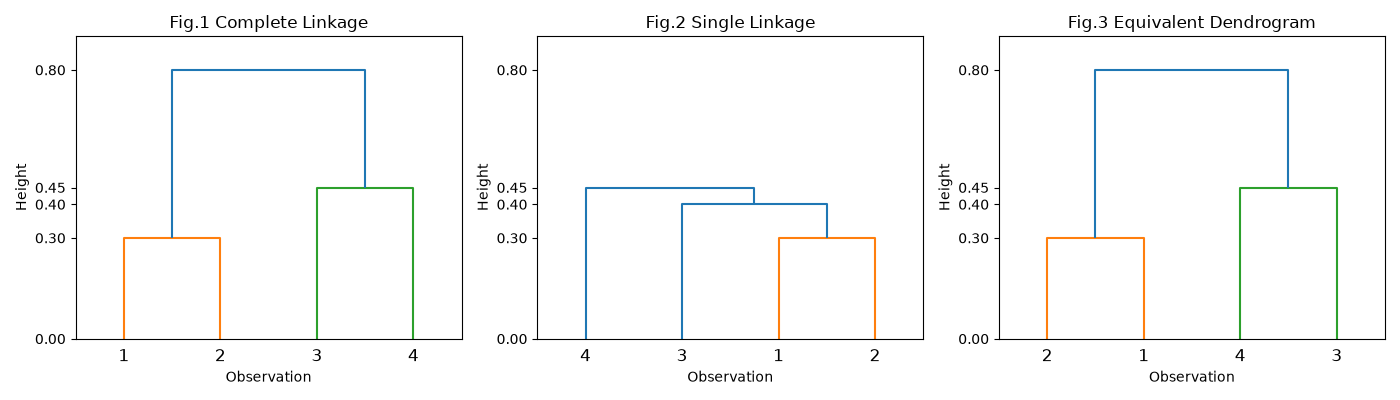


### (a)

The dendrogram is shown in Fig.1.

### (b)

The dendrogram is shown in Fig.2.

### (c)

The two clusters are {1, 2} and {3, 4}.

### (d)

The two clusters are {1, 2, 3} and {4}.

### (e)

The dendrogram is shown in Fig.3. The positions of observations 1 and 2, and observations 3 and 4 are swapped, but the meaning of the dendrogram is the same as Fig.1.